In [1]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import ks_2samp

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (16, 5)

In [3]:
CONFIG = {
    'TRAIN_PATH': r'../datasets_challenge/train',
    'TEST_PATH': r'../datasets_challenge/test',
    'COLUMNS_TO_DROP': ['sideSlip', 'vyCG', 'longitude', 'latitude', 'time'],
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': 'vxCG',
    'TARGET': 'sideSlip',
    'BATCH_SIZE': 128,
    'SEED': 42,
}

# Part 1: Data Loading

Load all dataloader variants and extract features for comparison

In [4]:
from utils.data_loadingV2 import load_data as load_v2_temporal
from utils.data_loadingV3_random import load_data as load_v3_random
from utils.data_loadingV4_file import load_data as load_v4_file

print("Loading V2: Temporal Split")
train_v2, val_v2, scaler_v2, _, _ = load_v2_temporal(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=0.15,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

print("\nLoading V3: Random Split")
train_v3, val_v3, scaler_v3, _, _ = load_v3_random(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=0.2,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

print("\nLoading V4: File-Based Split (File 7)")
train_v4, val_v4, scaler_v4, _, _ = load_v4_file(
    train_path=CONFIG['TRAIN_PATH'],
    val_file_num=7,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

Loading V2: Temporal Split
V5 Data Loader: Stratified Temporal Split

Processing 22 files...
Total groups after threshold: 42
Total groups after threshold: 42

Train: Many=90.3%, Medium=7.6%, Few=2.1%
Val:   Many=96.6%, Medium=2.3%, Few=1.1%

Train: 120,445 sequences | Val: 16,635 sequences


Loading V3: Random Split
V3 Data Loader: RANDOM Stratified Split (Better Generalization)

Processing 22 files...

Train: Many=90.3%, Medium=7.6%, Few=2.1%
Val:   Many=96.6%, Medium=2.3%, Few=1.1%

Train: 120,445 sequences | Val: 16,635 sequences


Loading V3: Random Split
V3 Data Loader: RANDOM Stratified Split (Better Generalization)

Processing 22 files...
Total groups: 42

✅ RANDOM Split (should match test distribution better):
Train: Many=92.0%, Medium=6.4%, Few=1.6%
Val:   Many=82.0%, Medium=12.2%, Few=5.7%
Total groups: 42

✅ RANDOM Split (should match test distribution better):
Train: Many=92.0%, Medium=6.4%, Few=1.6%
Val:   Many=82.0%, Medium=12.2%, Few=5.7%

Train: 124,692 sequences | Val

In [5]:
from utils.data_loadingV2 import load_test_data

print("Loading Test Data")
test_loader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    scaler=scaler_v3,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

Loading Test Data
📂 Loading Test Data (V1-Compatible)

Found 11 test files
🔧 Applying threshold per file: vxCG > 3.0 (grouping)

   test_part_001.csv         | 4 groups, 1,428 samples
   test_part_002.csv         | 1 groups, 10,190 samples
   test_part_003.csv         | No valid groups
   test_part_004.csv         | 2 groups, 6,914 samples
   test_part_005.csv         | 1 groups, 11,260 samples
   test_part_006.csv         | 1 groups, 10,256 samples
   test_part_007.csv         | 2 groups, 389 samples
   test_part_008.csv         | 2 groups, 3,177 samples
   test_part_009.csv         | 1 groups, 1,595 samples
   test_part_010.csv         | 1 groups, 3,168 samples
   test_part_011.csv         | 1 groups, 1,271 samples

✅ Total groups: 16

📊 Test Data Summary:
   Raw samples: 68,806
   After threshold: 49,648 (removed 19,158)
   Expected sequences: 49,628 (Kaggle expects 49,328)

✅ Test sequences: 49,328
   ✅ Count matches Kaggle requirement!



## Extract Features

In [6]:
def extract_features(loader, max_samples=50000):
    features = []
    targets = []
    count = 0
    
    for batch in loader:
        if len(batch) == 2:
            X, y = batch
            features.append(X[:, -1, :].cpu().numpy())
            targets.append(y.cpu().numpy())
        else:
            X = batch
            features.append(X[:, -1, :].cpu().numpy())
            targets.append(np.zeros(X.shape[0]))
        
        count += X.shape[0]
        if count >= max_samples:
            break
    
    features = np.vstack(features)[:max_samples]
    targets = np.concatenate(targets)[:max_samples]
    return features, targets

print("Extracting features...")
train_v2_X, train_v2_y = extract_features(train_v2)
val_v2_X, val_v2_y = extract_features(val_v2)

train_v3_X, train_v3_y = extract_features(train_v3)
val_v3_X, val_v3_y = extract_features(val_v3)

train_v4_X, train_v4_y = extract_features(train_v4)
val_v4_X, val_v4_y = extract_features(val_v4)

test_X, test_y = extract_features(test_loader)

print(f"\nV2 Temporal: Train {train_v2_X.shape}, Val {val_v2_X.shape}")
print(f"V3 Random:   Train {train_v3_X.shape}, Val {val_v3_X.shape}")
print(f"V4 File:     Train {train_v4_X.shape}, Val {val_v4_X.shape}")
print(f"Test:        {test_X.shape}")

Extracting features...

V2 Temporal: Train (50000, 22), Val (16635, 22)
V3 Random:   Train (50000, 22), Val (12388, 22)
V4 File:     Train (50000, 22), Val (1454, 22)
Test:        (49328, 22)

V2 Temporal: Train (50000, 22), Val (16635, 22)
V3 Random:   Train (50000, 22), Val (12388, 22)
V4 File:     Train (50000, 22), Val (1454, 22)
Test:        (49328, 22)


# Part 2: Distribution Analysis

Compare feature distributions using Jensen-Shannon divergence

In [7]:
def compute_distribution_distance(data1, data2, bins=50):
    """Compute Jensen-Shannon divergence between two distributions."""
    hist1, edges = np.histogram(data1, bins=bins, density=True)
    hist2, _ = np.histogram(data2, bins=edges, density=True)
    
    hist1 = hist1 + 1e-10
    hist2 = hist2 + 1e-10
    hist1 = hist1 / hist1.sum()
    hist2 = hist2 / hist2.sum()
    
    return jensenshannon(hist1, hist2)

def compute_ks_statistic(data1, data2):
    """Compute Kolmogorov-Smirnov test statistic."""
    statistic, pvalue = ks_2samp(data1, data2)
    return statistic, pvalue

num_features = train_v2_X.shape[1]

results = {
    'V2_Temporal': {'train_val': [], 'val_test': []},
    'V3_Random': {'train_val': [], 'val_test': []},
    'V4_File': {'train_val': [], 'val_test': []}
}

print("Computing distribution distances...")
for feat_idx in range(num_features):
    results['V2_Temporal']['train_val'].append(
        compute_distribution_distance(train_v2_X[:, feat_idx], val_v2_X[:, feat_idx])
    )
    results['V2_Temporal']['val_test'].append(
        compute_distribution_distance(val_v2_X[:, feat_idx], test_X[:, feat_idx])
    )
    
    results['V3_Random']['train_val'].append(
        compute_distribution_distance(train_v3_X[:, feat_idx], val_v3_X[:, feat_idx])
    )
    results['V3_Random']['val_test'].append(
        compute_distribution_distance(val_v3_X[:, feat_idx], test_X[:, feat_idx])
    )
    
    results['V4_File']['train_val'].append(
        compute_distribution_distance(train_v4_X[:, feat_idx], val_v4_X[:, feat_idx])
    )
    results['V4_File']['val_test'].append(
        compute_distribution_distance(val_v4_X[:, feat_idx], test_X[:, feat_idx])
    )

for key in results:
    results[key]['train_val'] = np.array(results[key]['train_val'])
    results[key]['val_test'] = np.array(results[key]['val_test'])

print("Done!")

Computing distribution distances...
Done!


## 2.1 Scatter Plot: Distribution Shift Visualization

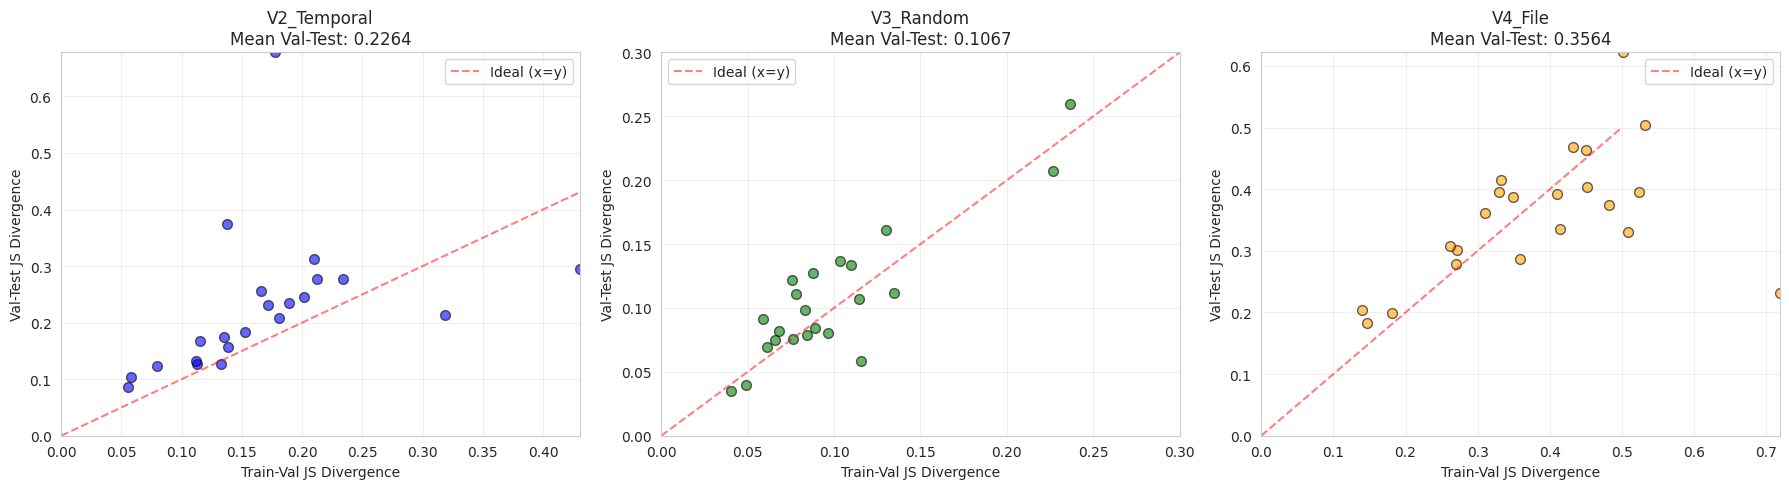


Interpretation:
- Lower Val-Test divergence = Better validation represents test
- Points closer to diagonal = Consistent split quality


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dataloaders = ['V2_Temporal', 'V3_Random', 'V4_File']
colors = ['blue', 'green', 'orange']

for i, (name, color) in enumerate(zip(dataloaders, colors)):
    axes[i].scatter(results[name]['train_val'], results[name]['val_test'], 
                   alpha=0.6, s=50, color=color, edgecolor='black')
    axes[i].plot([0, 0.5], [0, 0.5], 'r--', alpha=0.5, label='Ideal (x=y)')
    axes[i].set_xlabel('Train-Val JS Divergence')
    axes[i].set_ylabel('Val-Test JS Divergence')
    axes[i].set_title(f'{name}\nMean Val-Test: {results[name]["val_test"].mean():.4f}')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].set_xlim(0, max(results[name]['train_val'].max(), 0.3))
    axes[i].set_ylim(0, max(results[name]['val_test'].max(), 0.3))

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- Lower Val-Test divergence = Better validation represents test")
print("- Points closer to diagonal = Consistent split quality")

## 2.2 Summary: Best Dataloader Selection

In [9]:
summary = []

for name in dataloaders:
    train_val_mean = results[name]['train_val'].mean()
    val_test_mean = results[name]['val_test'].mean()
    val_test_std = results[name]['val_test'].std()
    
    summary.append({
        'Dataloader': name,
        'Train-Val Divergence': f"{train_val_mean:.4f}",
        'Val-Test Divergence': f"{val_test_mean:.4f}",
        'Val-Test Std': f"{val_test_std:.4f}",
        'Quality Score': f"{1 / (1 + val_test_mean):.4f}"
    })

summary_df = pd.DataFrame(summary)
print("\n" + "="*80)
print("DATALOADER COMPARISON SUMMARY")
print("="*80)
print(summary_df.to_string(index=False))

val_test_scores = {name: results[name]['val_test'].mean() for name in dataloaders}
best_idx = np.argmin(list(val_test_scores.values()))
best_loader = dataloaders[best_idx]

print("\nBest Dataloader: Lowest Val-Test Divergence")
print(f"Winner: {best_loader}")
print("="*80)


DATALOADER COMPARISON SUMMARY
 Dataloader Train-Val Divergence Val-Test Divergence Val-Test Std Quality Score
V2_Temporal               0.1692              0.2264       0.1228        0.8154
  V3_Random               0.0993              0.1067       0.0509        0.9036
    V4_File               0.3806              0.3564       0.1042        0.7373

Best Dataloader: Lowest Val-Test Divergence
Winner: V3_Random


## 2.3 Per-Feature Shift Analysis

In [10]:
for name in dataloaders:
    print(f"\n{name} - Top 5 Features with Largest Val-Test Shift:")
    top_indices = np.argsort(results[name]['val_test'])[-5:][::-1]
    for idx in top_indices:
        print(f"  Feature {idx:2d}: Val-Test JS = {results[name]['val_test'][idx]:.4f}")


V2_Temporal - Top 5 Features with Largest Val-Test Shift:
  Feature 20: Val-Test JS = 0.6779
  Feature 19: Val-Test JS = 0.3736
  Feature 21: Val-Test JS = 0.3117
  Feature 10: Val-Test JS = 0.2953
  Feature  2: Val-Test JS = 0.2775

V3_Random - Top 5 Features with Largest Val-Test Shift:
  Feature  3: Val-Test JS = 0.2598
  Feature  1: Val-Test JS = 0.2073
  Feature  4: Val-Test JS = 0.1612
  Feature 19: Val-Test JS = 0.1369
  Feature 20: Val-Test JS = 0.1337

V4_File - Top 5 Features with Largest Val-Test Shift:
  Feature 19: Val-Test JS = 0.6219
  Feature 20: Val-Test JS = 0.5047
  Feature 13: Val-Test JS = 0.4688
  Feature 21: Val-Test JS = 0.4643
  Feature 15: Val-Test JS = 0.4154


## 2.4 Worst Features: Distribution Histograms

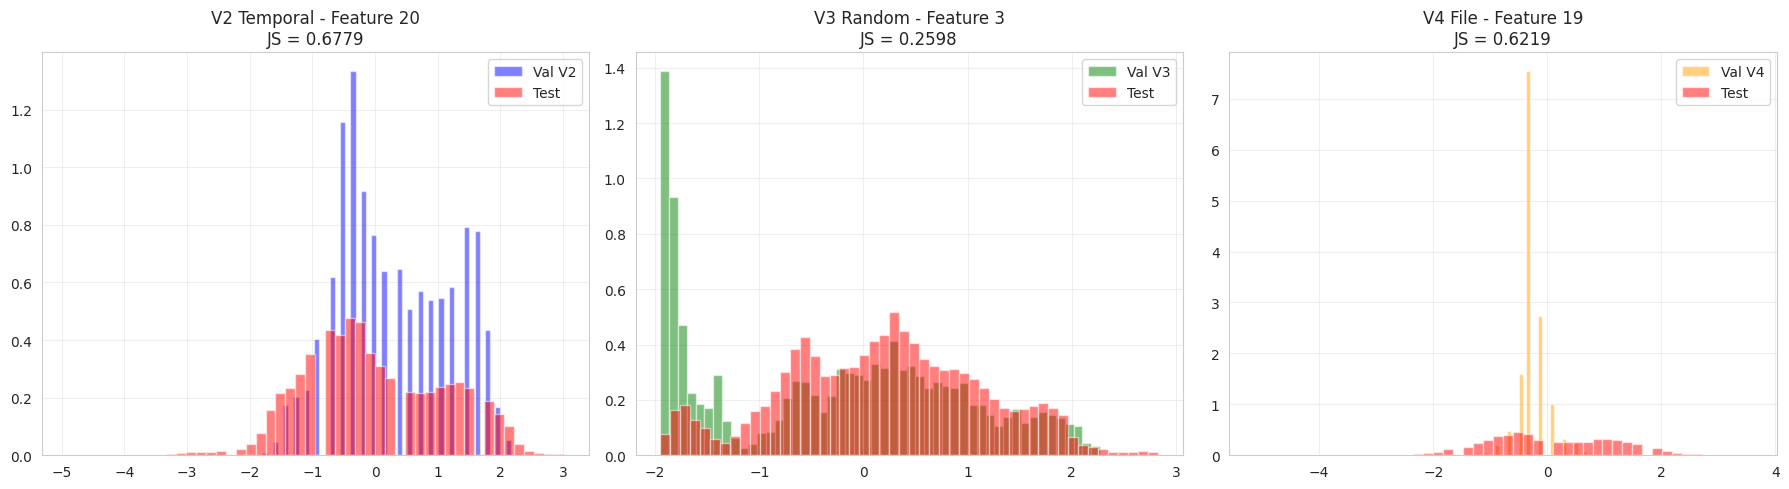

In [11]:
worst_feat_v2 = np.argmax(results['V2_Temporal']['val_test'])
worst_feat_v3 = np.argmax(results['V3_Random']['val_test'])
worst_feat_v4 = np.argmax(results['V4_File']['val_test'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(val_v2_X[:, worst_feat_v2], bins=50, alpha=0.5, label='Val V2', color='blue', density=True)
axes[0].hist(test_X[:, worst_feat_v2], bins=50, alpha=0.5, label='Test', color='red', density=True)
axes[0].set_title(f'V2 Temporal - Feature {worst_feat_v2}\nJS = {results["V2_Temporal"]["val_test"][worst_feat_v2]:.4f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(val_v3_X[:, worst_feat_v3], bins=50, alpha=0.5, label='Val V3', color='green', density=True)
axes[1].hist(test_X[:, worst_feat_v3], bins=50, alpha=0.5, label='Test', color='red', density=True)
axes[1].set_title(f'V3 Random - Feature {worst_feat_v3}\nJS = {results["V3_Random"]["val_test"][worst_feat_v3]:.4f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].hist(val_v4_X[:, worst_feat_v4], bins=50, alpha=0.5, label='Val V4', color='orange', density=True)
axes[2].hist(test_X[:, worst_feat_v4], bins=50, alpha=0.5, label='Test', color='red', density=True)
axes[2].set_title(f'V4 File - Feature {worst_feat_v4}\nJS = {results["V4_File"]["val_test"][worst_feat_v4]:.4f}')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2.5 Target (sideSlip) Distribution

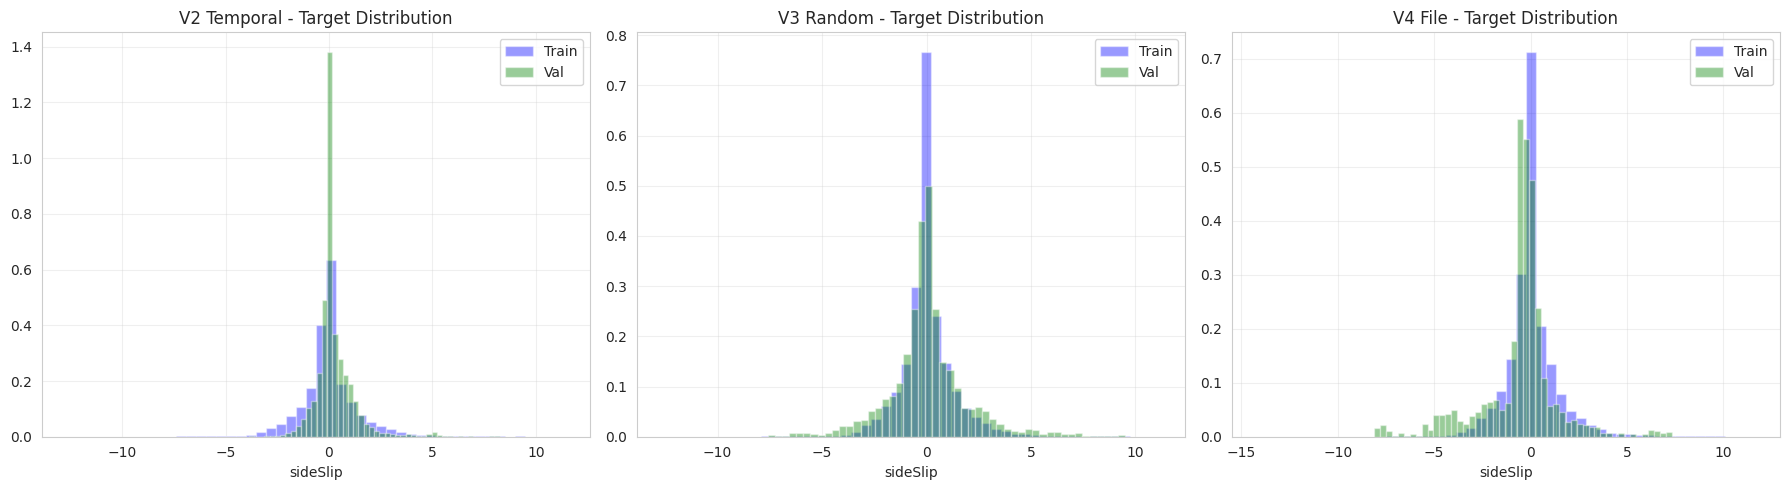


Target Distribution JS Divergence (Train-Val):
  V2 Temporal: 0.2012
  V3 Random:   0.1385
  V4 File:     0.2190


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(train_v2_y, bins=50, alpha=0.4, label='Train', color='blue', density=True)
axes[0].hist(val_v2_y, bins=50, alpha=0.4, label='Val', color='green', density=True)
axes[0].set_title('V2 Temporal - Target Distribution')
axes[0].set_xlabel('sideSlip')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(train_v3_y, bins=50, alpha=0.4, label='Train', color='blue', density=True)
axes[1].hist(val_v3_y, bins=50, alpha=0.4, label='Val', color='green', density=True)
axes[1].set_title('V3 Random - Target Distribution')
axes[1].set_xlabel('sideSlip')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].hist(train_v4_y, bins=50, alpha=0.4, label='Train', color='blue', density=True)
axes[2].hist(val_v4_y, bins=50, alpha=0.4, label='Val', color='green', density=True)
axes[2].set_title('V4 File - Target Distribution')
axes[2].set_xlabel('sideSlip')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

target_js_v2 = compute_distribution_distance(train_v2_y, val_v2_y)
target_js_v3 = compute_distribution_distance(train_v3_y, val_v3_y)
target_js_v4 = compute_distribution_distance(train_v4_y, val_v4_y)

print(f"\nTarget Distribution JS Divergence (Train-Val):")
print(f"  V2 Temporal: {target_js_v2:.4f}")
print(f"  V3 Random:   {target_js_v3:.4f}")
print(f"  V4 File:     {target_js_v4:.4f}")

# Part 3: Deep Feature Analysis

Comprehensive statistical analysis of the best dataloader's feature distributions

In [12]:
FEATURE_NAMES = ["handwheelAngle", "throttle", "brake", "vxCG", "axCG", "ayCG", 
                 "yawRate", "rollRate", "pitchRate", "rollAngle", "pitchAngle", 
                 "chassisAccelFL", "chassisAccelFR", "chassisAccelRL", "chassisAccelRR", 
                 "wheelAccelFL", "wheelAccelFR", "wheelAccelRL", "wheelAccelRR", 
                 "deflectionFL", "deflectionFR", "deflectionRR"]

def compute_feature_stats(data, dataset_name):
    """Compute comprehensive statistics for feature data."""
    stats = {
        'dataset': dataset_name,
        'mean': data.mean(axis=0),
        'std': data.std(axis=0),
        'min': data.min(axis=0),
        'max': data.max(axis=0),
        'q25': np.percentile(data, 25, axis=0),
        'median': np.percentile(data, 50, axis=0),
        'q75': np.percentile(data, 75, axis=0),
        'skewness': np.array([pd.Series(data[:, i]).skew() for i in range(data.shape[1])]),
        'kurtosis': np.array([pd.Series(data[:, i]).kurtosis() for i in range(data.shape[1])])
    }
    return stats

print("Computing comprehensive feature statistics...")
print("This analyzes mean, std, min, max, quartiles, skewness, kurtosis for all features\n")

best_loader_display = best_loader.replace('_', ' ')

if best_loader == 'V2_Temporal':
    train_best_X, val_best_X = train_v2_X, val_v2_X
elif best_loader == 'V3_Random':
    train_best_X, val_best_X = train_v3_X, val_v3_X
elif best_loader == 'V4_File':
    train_best_X, val_best_X = train_v4_X, val_v4_X
else:
    raise ValueError(f"Unknown best_loader: {best_loader}")

stats_train_best = compute_feature_stats(train_best_X, f'{best_loader_display} Train')
stats_val_best = compute_feature_stats(val_best_X, f'{best_loader_display} Val')
stats_test_data = compute_feature_stats(test_X, 'Test')

print(f"✅ Computed statistics for {best_loader_display} (best dataloader) and Test")

Computing comprehensive feature statistics...
This analyzes mean, std, min, max, quartiles, skewness, kurtosis for all features

✅ Computed statistics for V3 Random (best dataloader) and Test


## 3.1 Statistical Comparison Table

In [13]:
comparison_rows = []

for feat_idx, feat_name in enumerate(FEATURE_NAMES):
    row = {
        'Feature': feat_name,
        'Train_Mean': stats_train_best['mean'][feat_idx],
        'Val_Mean': stats_val_best['mean'][feat_idx],
        'Test_Mean': stats_test_data['mean'][feat_idx],
        'Train_Std': stats_train_best['std'][feat_idx],
        'Val_Std': stats_val_best['std'][feat_idx],
        'Test_Std': stats_test_data['std'][feat_idx],
        'Train-Val_Mean_Diff%': abs(stats_train_best['mean'][feat_idx] - stats_val_best['mean'][feat_idx]) / (abs(stats_train_best['mean'][feat_idx]) + 1e-8) * 100,
        'Val-Test_Mean_Diff%': abs(stats_val_best['mean'][feat_idx] - stats_test_data['mean'][feat_idx]) / (abs(stats_val_best['mean'][feat_idx]) + 1e-8) * 100,
        'Train-Val_Std_Diff%': abs(stats_train_best['std'][feat_idx] - stats_val_best['std'][feat_idx]) / (stats_train_best['std'][feat_idx] + 1e-8) * 100,
        'Val-Test_Std_Diff%': abs(stats_val_best['std'][feat_idx] - stats_test_data['std'][feat_idx]) / (stats_val_best['std'][feat_idx] + 1e-8) * 100,
    }
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

print("="*120)
print(f"FEATURE STATISTICS COMPARISON: {best_loader_display}")
print("="*120)
print("\nMean & Std Comparison:")
print(comparison_df[['Feature', 'Train_Mean', 'Val_Mean', 'Test_Mean', 
                     'Train_Std', 'Val_Std', 'Test_Std']].to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print("\n" + "="*120)
print("Difference Analysis (%):")
print("="*120)
print(comparison_df[['Feature', 'Train-Val_Mean_Diff%', 'Val-Test_Mean_Diff%', 
                     'Train-Val_Std_Diff%', 'Val-Test_Std_Diff%']].to_string(index=False, float_format=lambda x: f'{x:.2f}%'))

print("\n⚠️  Features with >10% Val-Test Mean Difference:")
high_diff_features = comparison_df[comparison_df['Val-Test_Mean_Diff%'] > 10]['Feature'].tolist()
if high_diff_features:
    for feat in high_diff_features:
        diff = comparison_df[comparison_df['Feature'] == feat]['Val-Test_Mean_Diff%'].values[0]
        print(f"   {feat}: {diff:.2f}%")
else:
    print("   ✅ None - All features have <10% difference")

FEATURE STATISTICS COMPARISON: V3 Random

Mean & Std Comparison:
       Feature  Train_Mean  Val_Mean  Test_Mean  Train_Std  Val_Std  Test_Std
handwheelAngle     -0.0006    0.1886     0.0906     0.9773   1.2304    0.9640
      throttle     -0.0033   -0.0462     0.1896     0.9966   1.0924    1.1487
         brake      0.0035    0.1095     0.1028     1.0054   1.0988    1.0884
          vxCG      0.0052   -0.2777     0.1878     0.9935   1.2170    0.9550
          axCG     -0.0043   -0.0330     0.0071     0.9995   0.9842    1.1155
          ayCG     -0.0008    0.1123     0.0707     1.0042   0.9199    1.0905
       yawRate     -0.0016    0.1353     0.0845     1.0021   0.9482    1.0388
      rollRate     -0.0020    0.0040     0.0074     0.9856   0.9927    1.1789
     pitchRate     -0.0023   -0.0257    -0.0206     0.9987   1.1076    1.2051
     rollAngle     -0.0054   -0.0406    -0.0898     1.0027   1.0545    1.0284
    pitchAngle      0.0086    0.0566     0.0338     1.0019   1.0894    1.1175

## 3.2 Distribution Shape (Skewness & Kurtosis)

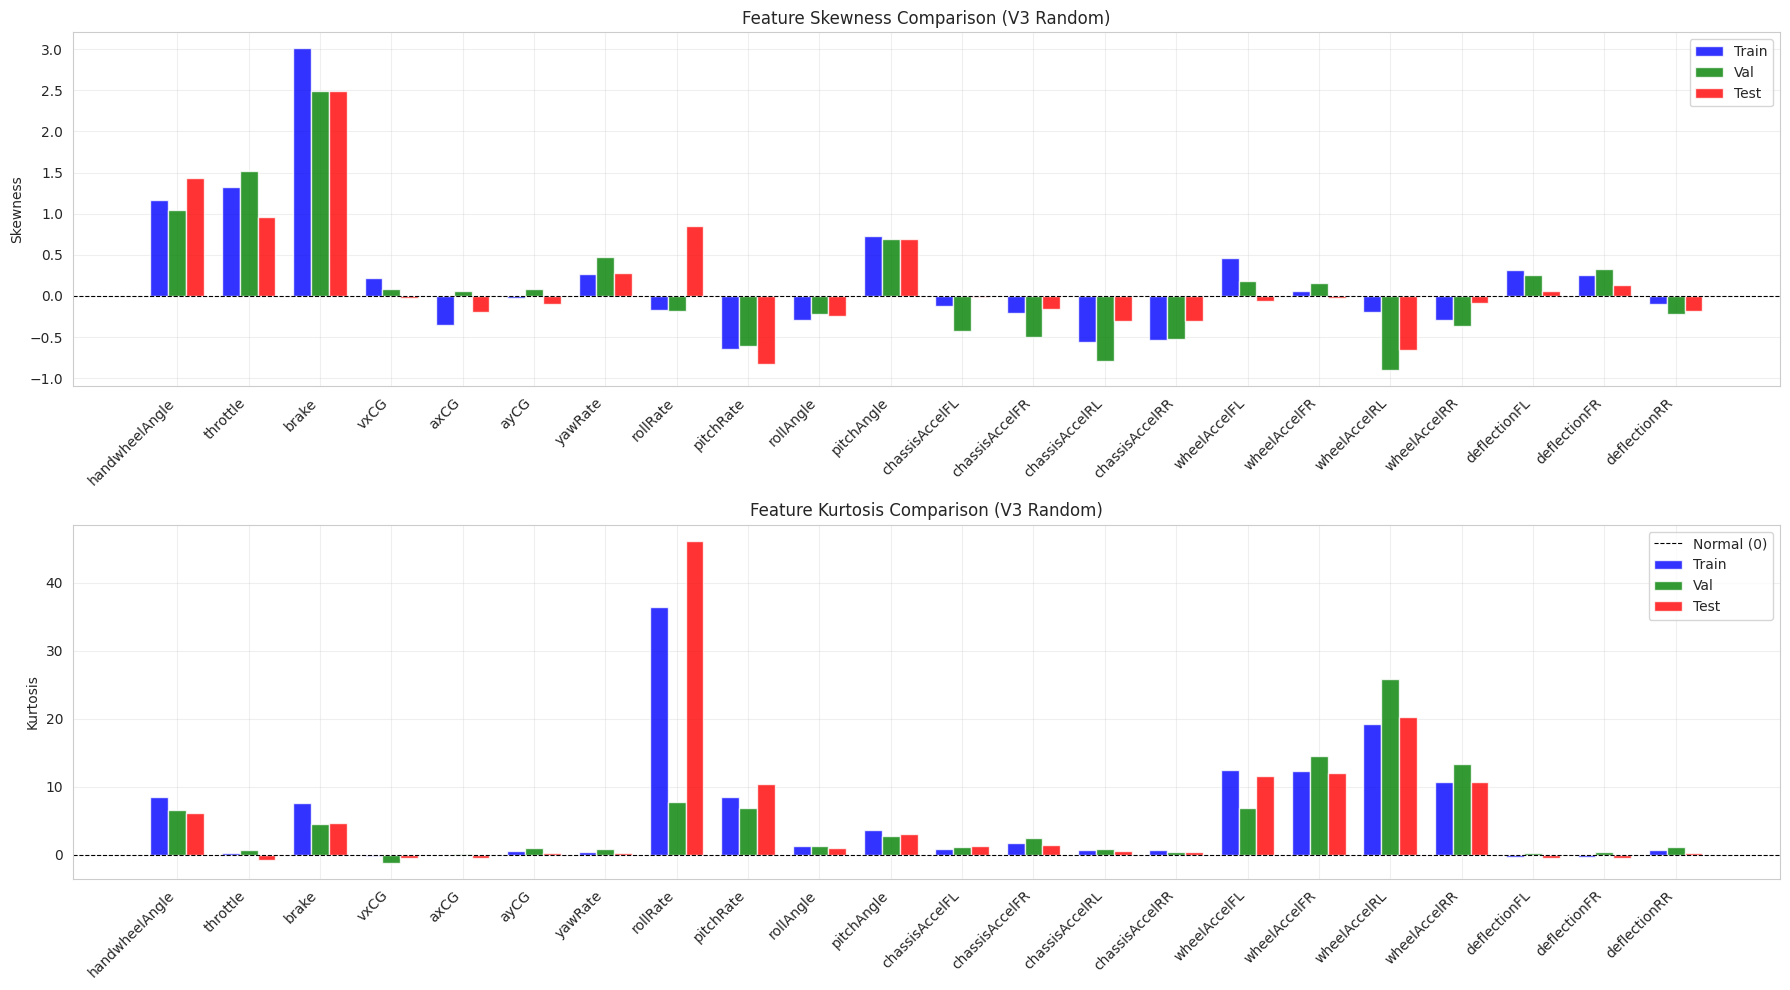


Interpretation:
- Skewness: 0=symmetric, >0=right-tailed, <0=left-tailed
- Kurtosis: 0=normal, >0=heavy-tailed (outliers), <0=light-tailed

Mismatches in skewness/kurtosis indicate different distribution shapes between val and test


In [15]:
fig, axes = plt.subplots(2, 1, figsize=(18, 10))

x_pos = np.arange(len(FEATURE_NAMES))
width = 0.25

axes[0].bar(x_pos - width, stats_train_best['skewness'], width, label='Train', alpha=0.8, color='blue')
axes[0].bar(x_pos, stats_val_best['skewness'], width, label='Val', alpha=0.8, color='green')
axes[0].bar(x_pos + width, stats_test_data['skewness'], width, label='Test', alpha=0.8, color='red')
axes[0].axhline(y=0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_ylabel('Skewness')
axes[0].set_title(f'Feature Skewness Comparison ({best_loader_display})')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(FEATURE_NAMES, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar(x_pos - width, stats_train_best['kurtosis'], width, label='Train', alpha=0.8, color='blue')
axes[1].bar(x_pos, stats_val_best['kurtosis'], width, label='Val', alpha=0.8, color='green')
axes[1].bar(x_pos + width, stats_test_data['kurtosis'], width, label='Test', alpha=0.8, color='red')
axes[1].axhline(y=0, color='black', linestyle='--', linewidth=0.8, label='Normal (0)')
axes[1].set_ylabel('Kurtosis')
axes[1].set_title(f'Feature Kurtosis Comparison ({best_loader_display})')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(FEATURE_NAMES, rotation=45, ha='right')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- Skewness: 0=symmetric, >0=right-tailed, <0=left-tailed")
print("- Kurtosis: 0=normal, >0=heavy-tailed (outliers), <0=light-tailed")
print("\nMismatches in skewness/kurtosis indicate different distribution shapes between val and test")

## 3.3 Correlation Matrix: Feature Relationships

Computing correlation matrices...


/tmp/ipykernel_140009/155899385.py:71: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/mdesouky/workspace/mait_g2_drift_challenge/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mdesouky/workspace/mait_g2_drift_challenge/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


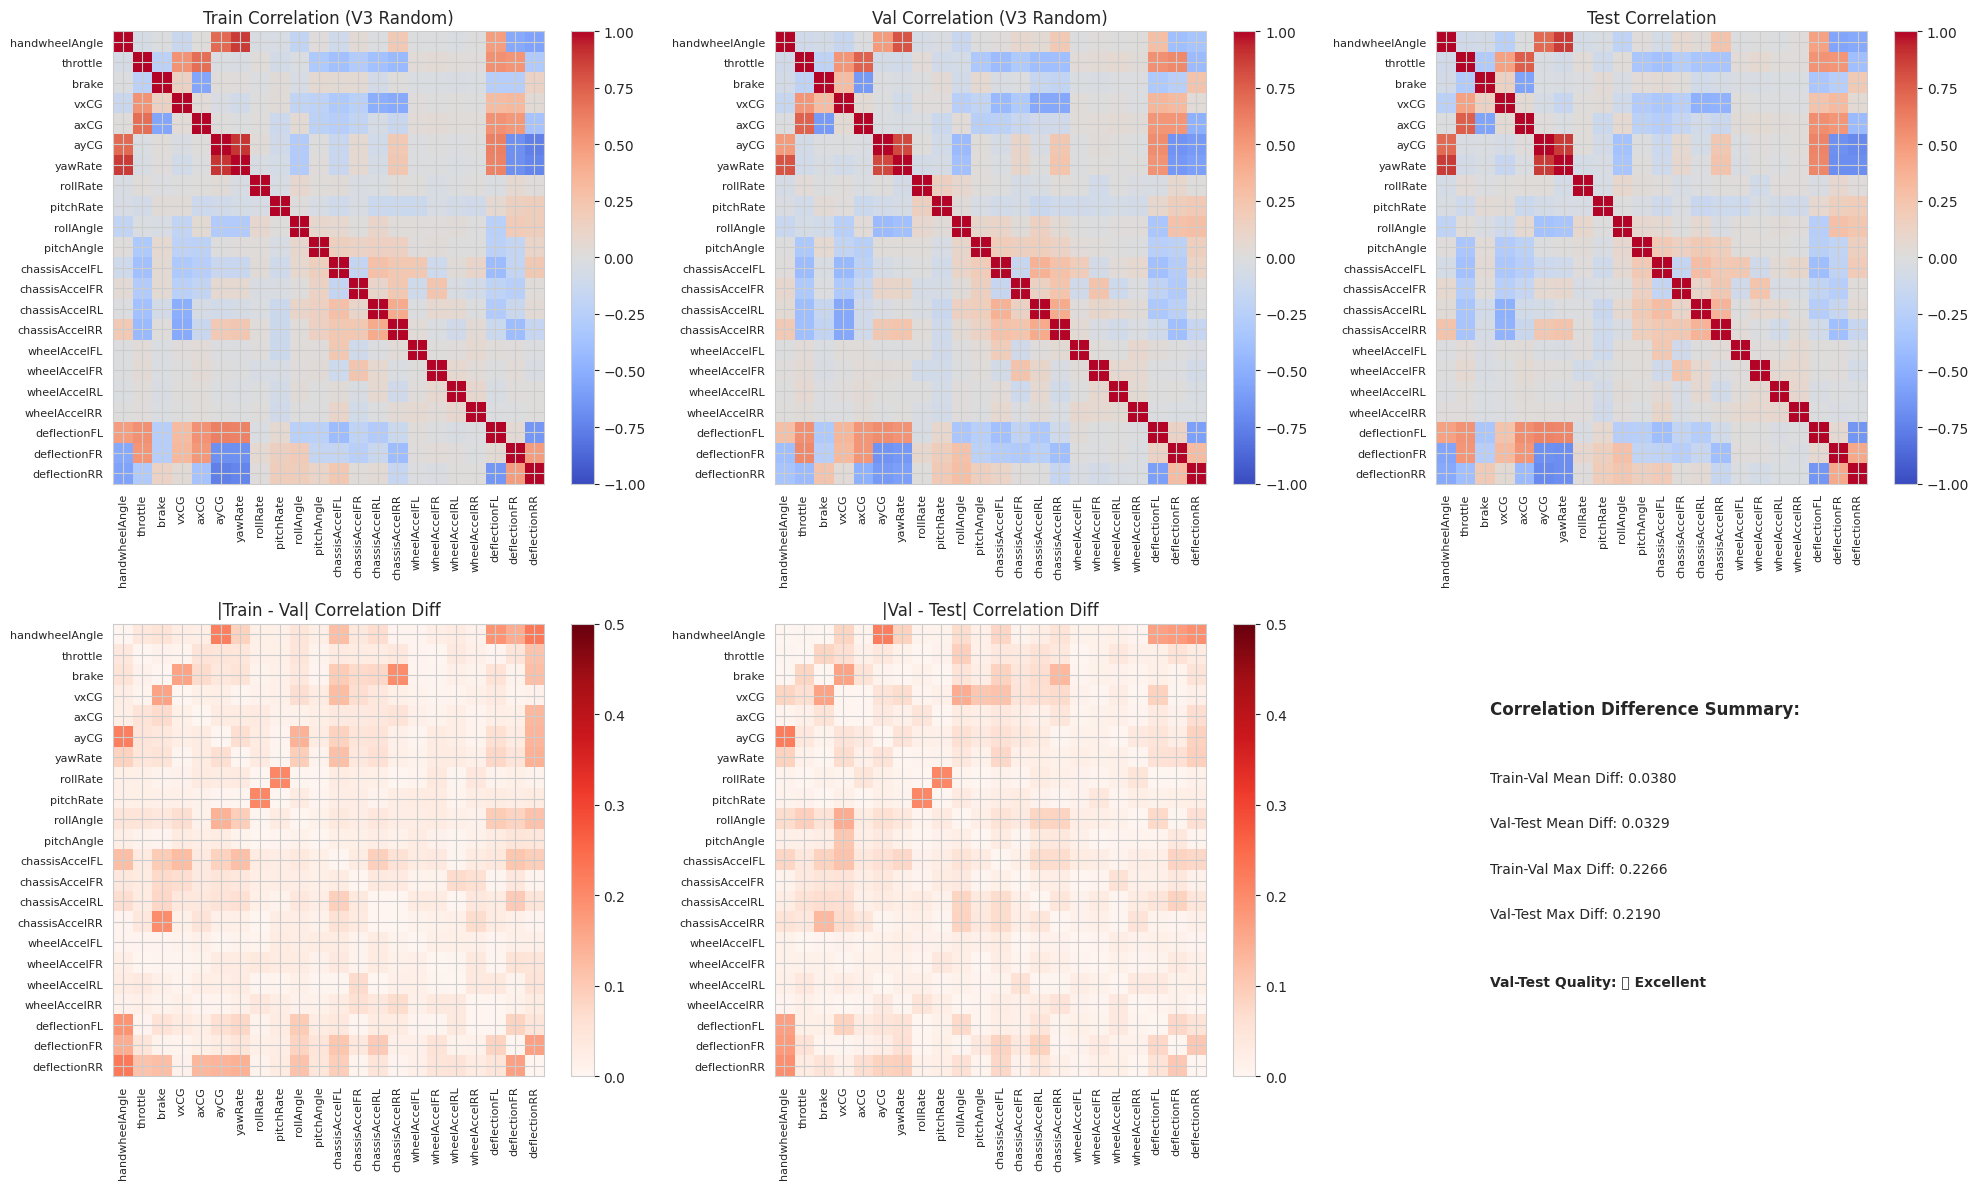


Correlation Structure Analysis:
  Train-Val Mean Difference: 0.0380
  Val-Test Mean Difference:  0.0329

Interpretation: Lower difference = Feature relationships preserved between datasets


In [15]:
print("Computing correlation matrices...")
corr_train_best = np.corrcoef(train_best_X.T)
corr_val_best = np.corrcoef(val_best_X.T)
corr_test_data = np.corrcoef(test_X.T)

corr_diff_train_val = np.abs(corr_train_best - corr_val_best)
corr_diff_val_test = np.abs(corr_val_best - corr_test_data)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

im1 = axes[0, 0].imshow(corr_train_best, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
axes[0, 0].set_title(f'Train Correlation ({best_loader_display})')
axes[0, 0].set_xticks(range(len(FEATURE_NAMES)))
axes[0, 0].set_yticks(range(len(FEATURE_NAMES)))
axes[0, 0].set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=8)
axes[0, 0].set_yticklabels(FEATURE_NAMES, fontsize=8)
plt.colorbar(im1, ax=axes[0, 0])

im2 = axes[0, 1].imshow(corr_val_best, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
axes[0, 1].set_title(f'Val Correlation ({best_loader_display})')
axes[0, 1].set_xticks(range(len(FEATURE_NAMES)))
axes[0, 1].set_yticks(range(len(FEATURE_NAMES)))
axes[0, 1].set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=8)
axes[0, 1].set_yticklabels(FEATURE_NAMES, fontsize=8)
plt.colorbar(im2, ax=axes[0, 1])

im3 = axes[0, 2].imshow(corr_test_data, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
axes[0, 2].set_title('Test Correlation')
axes[0, 2].set_xticks(range(len(FEATURE_NAMES)))
axes[0, 2].set_yticks(range(len(FEATURE_NAMES)))
axes[0, 2].set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=8)
axes[0, 2].set_yticklabels(FEATURE_NAMES, fontsize=8)
plt.colorbar(im3, ax=axes[0, 2])

im4 = axes[1, 0].imshow(corr_diff_train_val, cmap='Reds', vmin=0, vmax=0.5, aspect='auto')
axes[1, 0].set_title('|Train - Val| Correlation Diff')
axes[1, 0].set_xticks(range(len(FEATURE_NAMES)))
axes[1, 0].set_yticks(range(len(FEATURE_NAMES)))
axes[1, 0].set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=8)
axes[1, 0].set_yticklabels(FEATURE_NAMES, fontsize=8)
plt.colorbar(im4, ax=axes[1, 0])

im5 = axes[1, 1].imshow(corr_diff_val_test, cmap='Reds', vmin=0, vmax=0.5, aspect='auto')
axes[1, 1].set_title('|Val - Test| Correlation Diff')
axes[1, 1].set_xticks(range(len(FEATURE_NAMES)))
axes[1, 1].set_yticks(range(len(FEATURE_NAMES)))
axes[1, 1].set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=8)
axes[1, 1].set_yticklabels(FEATURE_NAMES, fontsize=8)
plt.colorbar(im5, ax=axes[1, 1])

axes[1, 2].axis('off')
corr_train_val_mean_diff = corr_diff_train_val[np.triu_indices_from(corr_diff_train_val, k=1)].mean()
corr_val_test_mean_diff = corr_diff_val_test[np.triu_indices_from(corr_diff_val_test, k=1)].mean()
corr_train_val_max_diff = corr_diff_train_val[np.triu_indices_from(corr_diff_train_val, k=1)].max()
corr_val_test_max_diff = corr_diff_val_test[np.triu_indices_from(corr_diff_val_test, k=1)].max()

axes[1, 2].text(0.1, 0.8, "Correlation Difference Summary:", fontsize=12, fontweight='bold', transform=axes[1, 2].transAxes)
axes[1, 2].text(0.1, 0.65, f"Train-Val Mean Diff: {corr_train_val_mean_diff:.4f}", fontsize=10, transform=axes[1, 2].transAxes)
axes[1, 2].text(0.1, 0.55, f"Val-Test Mean Diff: {corr_val_test_mean_diff:.4f}", fontsize=10, transform=axes[1, 2].transAxes)
axes[1, 2].text(0.1, 0.45, f"Train-Val Max Diff: {corr_train_val_max_diff:.4f}", fontsize=10, transform=axes[1, 2].transAxes)
axes[1, 2].text(0.1, 0.35, f"Val-Test Max Diff: {corr_val_test_max_diff:.4f}", fontsize=10, transform=axes[1, 2].transAxes)

if corr_val_test_mean_diff < 0.05:
    corr_status = "✅ Excellent"
elif corr_val_test_mean_diff < 0.10:
    corr_status = "✅ Good"
else:
    corr_status = "⚠️  Moderate"
axes[1, 2].text(0.1, 0.2, f"Val-Test Quality: {corr_status}", fontsize=10, fontweight='bold', transform=axes[1, 2].transAxes)

plt.tight_layout()
plt.show()

print("\nCorrelation Structure Analysis:")
print(f"  Train-Val Mean Difference: {corr_train_val_mean_diff:.4f}")
print(f"  Val-Test Mean Difference:  {corr_val_test_mean_diff:.4f}")
print(f"\nInterpretation: Lower difference = Feature relationships preserved between datasets")

## 3.4 Range & Outlier Analysis

In [17]:
def compute_outlier_percentage(data, method='iqr'):
    """Compute percentage of outliers using IQR method."""
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = ((data < lower_bound) | (data > upper_bound)).sum()
    return (outliers / len(data)) * 100

outlier_rows = []
for feat_idx, feat_name in enumerate(FEATURE_NAMES):
    train_outlier_pct = compute_outlier_percentage(train_best_X[:, feat_idx])
    val_outlier_pct = compute_outlier_percentage(val_best_X[:, feat_idx])
    test_outlier_pct = compute_outlier_percentage(test_X[:, feat_idx])
    
    train_range_val = stats_train_best['max'][feat_idx] - stats_train_best['min'][feat_idx]
    val_range_val = stats_val_best['max'][feat_idx] - stats_val_best['min'][feat_idx]
    test_range_val = stats_test_data['max'][feat_idx] - stats_test_data['min'][feat_idx]
    
    outlier_rows.append({
        'Feature': feat_name,
        'Train_Range': train_range_val,
        'Val_Range': val_range_val,
        'Test_Range': test_range_val,
        'Train_Outliers%': train_outlier_pct,
        'Val_Outliers%': val_outlier_pct,
        'Test_Outliers%': test_outlier_pct,
        'Val-Test_Range_Ratio': val_range_val / (test_range_val + 1e-8),
        'Val-Test_Outlier_Diff%': abs(val_outlier_pct - test_outlier_pct)
    })

outlier_df = pd.DataFrame(outlier_rows)

print("="*120)
print("RANGE & OUTLIER ANALYSIS")
print("="*120)
print("\nRange Comparison:")
print(outlier_df[['Feature', 'Train_Range', 'Val_Range', 'Test_Range', 'Val-Test_Range_Ratio']].to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print("\n" + "="*120)
print("Outlier Percentage (IQR Method):")
print("="*120)
print(outlier_df[['Feature', 'Train_Outliers%', 'Val_Outliers%', 'Test_Outliers%', 'Val-Test_Outlier_Diff%']].to_string(index=False, float_format=lambda x: f'{x:.2f}'))

print("\n⚠️  Features with Val-Test Range Ratio outside [0.8, 1.2]:")
extreme_ranges = outlier_df[(outlier_df['Val-Test_Range_Ratio'] < 0.8) | (outlier_df['Val-Test_Range_Ratio'] > 1.2)]
if len(extreme_ranges) > 0:
    for _, row in extreme_ranges.iterrows():
        print(f"   {row['Feature']}: Ratio = {row['Val-Test_Range_Ratio']:.2f}")
else:
    print("   ✅ None - All features have similar ranges")

print("\n⚠️  Features with >5% Outlier Percentage Difference:")
outlier_high_diff = outlier_df[outlier_df['Val-Test_Outlier_Diff%'] > 5]
if len(outlier_high_diff) > 0:
    for _, row in outlier_high_diff.iterrows():
        print(f"   {row['Feature']}: Diff = {row['Val-Test_Outlier_Diff%']:.2f}%")
else:
    print("   ✅ None - Outlier rates are consistent")

RANGE & OUTLIER ANALYSIS

Range Comparison:
       Feature  Train_Range  Val_Range  Test_Range  Val-Test_Range_Ratio
handwheelAngle      16.7114    12.3770     12.1187                1.0213
      throttle       3.2602     3.2504      3.2569                0.9980
         brake       4.4127     4.3774      4.4127                0.9920
          vxCG       4.9750     4.2191      4.7754                0.8835
          axCG       7.9512     6.8721      8.4583                0.8125
          ayCG      12.5326    10.4066     12.5450                0.8295
       yawRate       7.4223     6.5969      7.3544                0.8970
      rollRate      41.0867    20.1724     44.2114                0.4563
     pitchRate      21.6324    18.8638     32.7604                0.5758
     rollAngle       8.0129     7.6697      7.7662                0.9876
    pitchAngle       9.1952     8.7949      9.2260                0.9533
chassisAccelFL      13.3583    13.3307     16.9377                0.7870
chassis

## 3.5 Box Plot: Visual Distribution Check

/tmp/ipykernel_140009/320209847.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_to_plot, labels=['Train', 'Val', 'Test'], patch_artist=True)
/tmp/ipykernel_140009/320209847.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_to_plot, labels=['Train', 'Val', 'Test'], patch_artist=True)
/tmp/ipykernel_140009/320209847.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_to_plot, labels=['Train', 'Val', 'Test'], patch_artist=True)
/tmp/ipykernel_140009/320209847.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has 

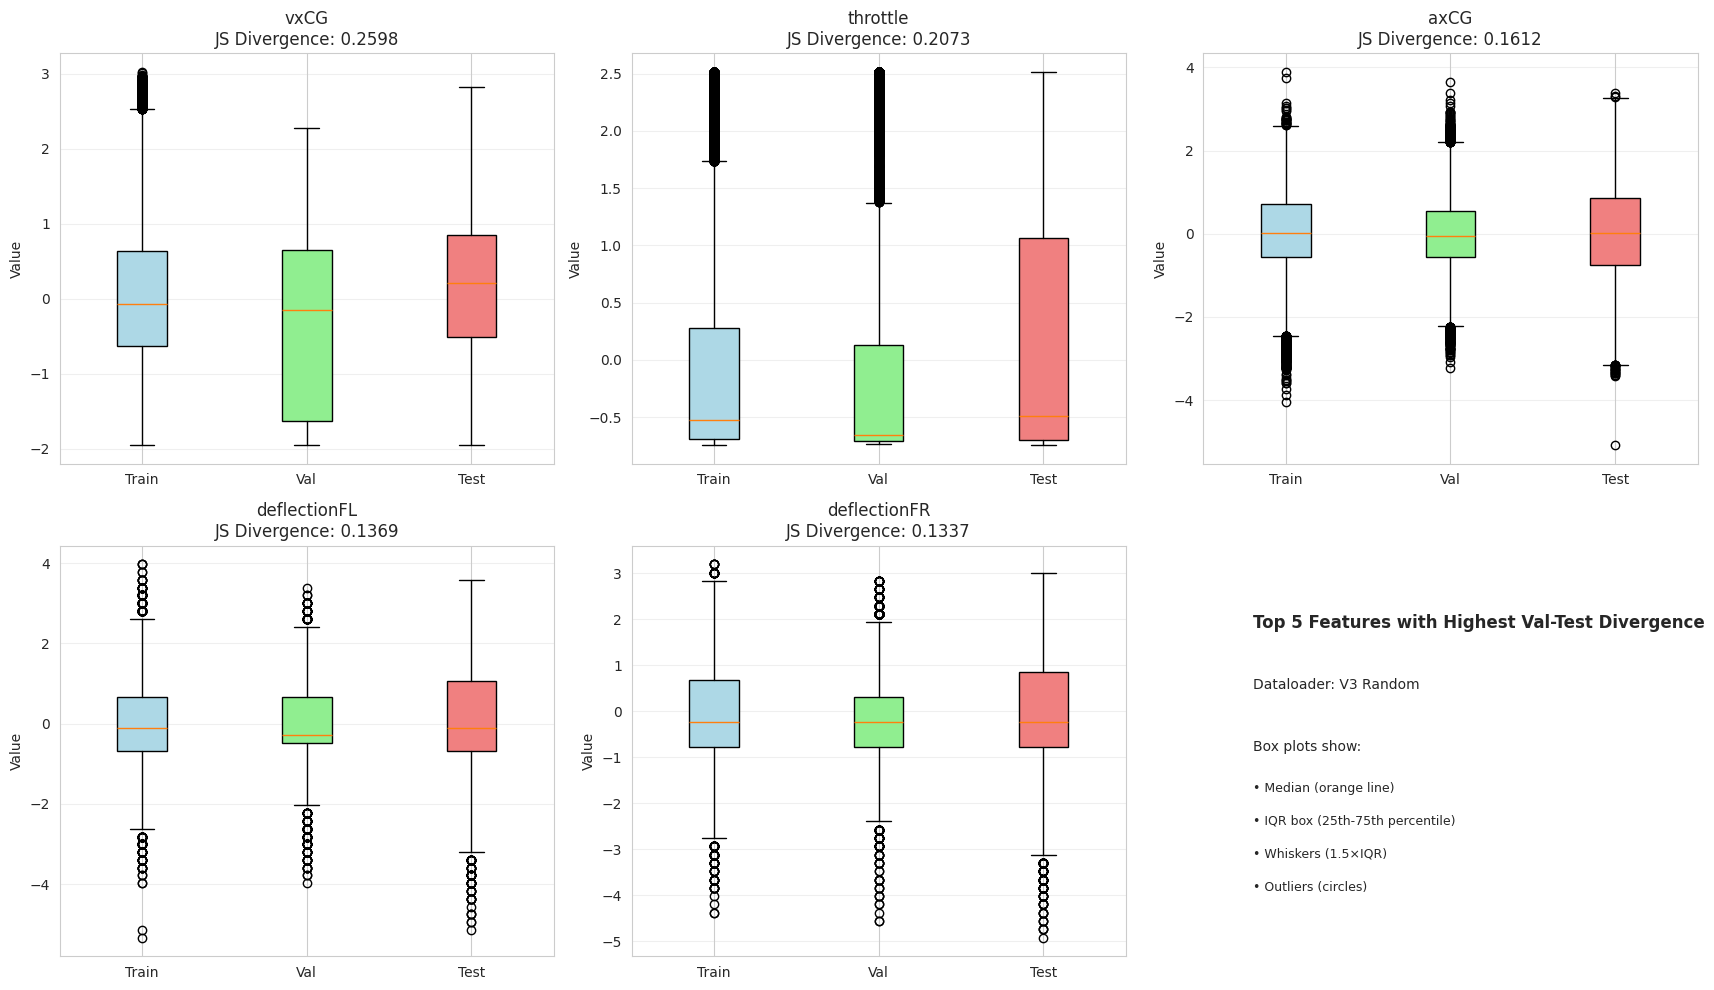


Top 5 Features with Highest Distribution Shift:
1. vxCG: JS = 0.2598
2. throttle: JS = 0.2073
3. axCG: JS = 0.1612
4. deflectionFL: JS = 0.1369
5. deflectionFR: JS = 0.1337


In [18]:
top_5_worst_feat_idx = np.argsort(results[best_loader]['val_test'])[-5:][::-1]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat_idx in enumerate(top_5_worst_feat_idx):
    feat_name = FEATURE_NAMES[feat_idx]
    
    data_to_plot = [
        train_best_X[:, feat_idx],
        val_best_X[:, feat_idx],
        test_X[:, feat_idx]
    ]
    
    bp = axes[i].boxplot(data_to_plot, labels=['Train', 'Val', 'Test'], patch_artist=True)
    
    box_colors = ['lightblue', 'lightgreen', 'lightcoral']
    for patch, color in zip(bp['boxes'], box_colors):
        patch.set_facecolor(color)
    
    axes[i].set_title(f'{feat_name}\nJS Divergence: {results[best_loader]["val_test"][feat_idx]:.4f}')
    axes[i].grid(True, alpha=0.3, axis='y')
    axes[i].set_ylabel('Value')

axes[5].axis('off')
axes[5].text(0.1, 0.8, "Top 5 Features with Highest Val-Test Divergence", 
             fontsize=12, fontweight='bold', transform=axes[5].transAxes)
axes[5].text(0.1, 0.65, f"Dataloader: {best_loader_display}", 
             fontsize=10, transform=axes[5].transAxes)
axes[5].text(0.1, 0.5, "Box plots show:", 
             fontsize=10, transform=axes[5].transAxes)
axes[5].text(0.1, 0.4, "• Median (orange line)", 
             fontsize=9, transform=axes[5].transAxes)
axes[5].text(0.1, 0.32, "• IQR box (25th-75th percentile)", 
             fontsize=9, transform=axes[5].transAxes)
axes[5].text(0.1, 0.24, "• Whiskers (1.5×IQR)", 
             fontsize=9, transform=axes[5].transAxes)
axes[5].text(0.1, 0.16, "• Outliers (circles)", 
             fontsize=9, transform=axes[5].transAxes)

plt.tight_layout()
plt.show()

print("\nTop 5 Features with Highest Distribution Shift:")
for i, feat_idx in enumerate(top_5_worst_feat_idx, 1):
    print(f"{i}. {FEATURE_NAMES[feat_idx]}: JS = {results[best_loader]['val_test'][feat_idx]:.4f}")

## 3.6 Comprehensive Quality Assessment

In [19]:
print("="*120)
print(f"DEEP FEATURE ANALYSIS SUMMARY: {best_loader_display}")
print("="*120)

print("\n1. DISTRIBUTION METRICS")
print("-" * 120)
mean_js_divergence = results[best_loader]['val_test'].mean()
print(f"   Mean JS Divergence (Val-Test): {mean_js_divergence:.4f}")

if mean_js_divergence < 0.05:
    js_quality = "EXCELLENT ✅"
elif mean_js_divergence < 0.10:
    js_quality = "GOOD ✅"
elif mean_js_divergence < 0.15:
    js_quality = "MODERATE ⚠️"
else:
    js_quality = "POOR ❌"
print(f"   Overall Quality: {js_quality}")

print("\n2. STATISTICAL DIFFERENCES")
print("-" * 120)
high_mean_diff_count = (comparison_df['Val-Test_Mean_Diff%'] > 10).sum()
high_std_diff_count = (comparison_df['Val-Test_Std_Diff%'] > 10).sum()
print(f"   Features with >10% Mean Difference: {high_mean_diff_count}/{len(FEATURE_NAMES)}")
print(f"   Features with >10% Std Difference:  {high_std_diff_count}/{len(FEATURE_NAMES)}")

print("\n3. CORRELATION STRUCTURE")
print("-" * 120)
print(f"   Train-Val Correlation Diff: {corr_train_val_mean_diff:.4f}")
print(f"   Val-Test Correlation Diff:  {corr_val_test_mean_diff:.4f}")
if corr_val_test_mean_diff < 0.05:
    corr_quality = "EXCELLENT ✅ - Feature relationships preserved"
elif corr_val_test_mean_diff < 0.10:
    corr_quality = "GOOD ✅ - Minor differences in relationships"
else:
    corr_quality = "MODERATE ⚠️ - Significant relationship changes"
print(f"   Assessment: {corr_quality}")

print("\n4. RANGE & OUTLIERS")
print("-" * 120)
extreme_range_count = len(outlier_df[(outlier_df['Val-Test_Range_Ratio'] < 0.8) | (outlier_df['Val-Test_Range_Ratio'] > 1.2)])
extreme_outlier_count = len(outlier_df[outlier_df['Val-Test_Outlier_Diff%'] > 5])
print(f"   Features with extreme range mismatch: {extreme_range_count}/{len(FEATURE_NAMES)}")
print(f"   Features with outlier rate mismatch:  {extreme_outlier_count}/{len(FEATURE_NAMES)}")

print("\n5. DISTRIBUTION SHAPE")
print("-" * 120)
skew_diff_array = np.abs(stats_val_best['skewness'] - stats_test_data['skewness'])
kurt_diff_array = np.abs(stats_val_best['kurtosis'] - stats_test_data['kurtosis'])
high_skew_diff_count = (skew_diff_array > 0.5).sum()
high_kurt_diff_count = (kurt_diff_array > 1.0).sum()
print(f"   Features with high skewness difference (>0.5): {high_skew_diff_count}/{len(FEATURE_NAMES)}")
print(f"   Features with high kurtosis difference (>1.0): {high_kurt_diff_count}/{len(FEATURE_NAMES)}")

print("\n6. TOP PROBLEMATIC FEATURES")
print("-" * 120)
for i, idx in enumerate(top_5_worst_feat_idx, 1):
    feat = FEATURE_NAMES[idx]
    js_val = results[best_loader]['val_test'][idx]
    mean_diff_val = comparison_df[comparison_df['Feature'] == feat]['Val-Test_Mean_Diff%'].values[0]
    std_diff_val = comparison_df[comparison_df['Feature'] == feat]['Val-Test_Std_Diff%'].values[0]
    print(f"   {i}. {feat:20s} | JS={js_val:.4f} | Mean Diff={mean_diff_val:.2f}% | Std Diff={std_diff_val:.2f}%")

print("\n7. OVERALL ASSESSMENT")
print("=" * 120)

quality_score = 100
if mean_js_divergence > 0.10: quality_score -= 20
if high_mean_diff_count > 5: quality_score -= 15
if corr_val_test_mean_diff > 0.10: quality_score -= 15
if extreme_range_count > 3: quality_score -= 10
if high_skew_diff_count > 5: quality_score -= 10

if quality_score >= 90:
    overall_verdict = "EXCELLENT ✅ - Val is highly representative of Test"
elif quality_score >= 75:
    overall_verdict = "GOOD ✅ - Val is reasonably representative of Test"
elif quality_score >= 60:
    overall_verdict = "MODERATE ⚠️ - Some distribution shift exists"
else:
    overall_verdict = "POOR ❌ - Significant distribution shift"

print(f"\n   Quality Score: {quality_score}/100")
print(f"   Verdict: {overall_verdict}")
print(f"\n   Recommendation: {'Use this dataloader for training' if quality_score >= 75 else 'Consider different split strategy'}")

print("\n" + "="*120)

DEEP FEATURE ANALYSIS SUMMARY: V3 Random

1. DISTRIBUTION METRICS
------------------------------------------------------------------------------------------------------------------------
   Mean JS Divergence (Val-Test): 0.1067
   Overall Quality: MODERATE ⚠️

2. STATISTICAL DIFFERENCES
------------------------------------------------------------------------------------------------------------------------
   Features with >10% Mean Difference: 20/22
   Features with >10% Std Difference:  9/22

3. CORRELATION STRUCTURE
------------------------------------------------------------------------------------------------------------------------
   Train-Val Correlation Diff: 0.0380
   Val-Test Correlation Diff:  0.0329
   Assessment: EXCELLENT ✅ - Feature relationships preserved

4. RANGE & OUTLIERS
------------------------------------------------------------------------------------------------------------------------
   Features with extreme range mismatch: 4/22
   Features with outlier rate 